### Set Parameters

In [1]:
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))

from IPython import display
from matplotlib import pyplot as plt
import torch
import bindsnet
import os
import numpy as np
import math

from time import time as t

from bindsnet.network import Network
from bindsnet.learning import WeightDependentPostPre
from bindsnet.learning import NoOp
from bindsnet.encoding import bernoulli_loader
from bindsnet.network.monitors import NetworkMonitor
from bindsnet.network.nodes import Input, LIFNodes,IFNodes
from bindsnet.network.topology import Connection

num_of_classes = 6
num_in = 8

digits = [[[1.0, 1.0],
           [0.1, 0.1]],
          
           [[0.1, 0.1],
           [1.0, 1.0]],
          
          [[1.0, 0.1],
           [1.0, 0.1]],
          
          [[0.1, 1.0],
           [0.1, 1.0]],
          
          [[1.0, 0.1],
           [0.1, 1.0]],
          
          [[0.1, 1.0],
           [1.0, 0.1]],
             ]

def invert(digits):
    
    digits_inverted = []

    for n,digit in enumerate(digits):
    
        temp = []
    
        for i,raw in enumerate(digit):
        
            temp_1 = []
        
            for k in range(len(raw)):
            
                temp_1.append(1 - digits[n][i][k] + 0.1)
        
            temp.append(temp_1.copy())
    
        digits_inverted.append(temp.copy())

    return digits_inverted


digits_inverted = invert(digits)

def dataset(num):
    X = []
    y = torch.Tensor()
    digits_markers = torch.eye(num_of_classes) 
        
    for i in np.arange(num):

        for index in range(num_of_classes):

            X.append(digits[index] + digits_inverted[index])
            y = torch.cat((y, digits_markers[index]),0)

    X = torch.tensor(X).reshape(num*num_of_classes, 8)
    y = y.reshape(num*num_of_classes, num_of_classes)

    return X,y

weights_rand_dist_XY = np.random.normal(0.5, 0.05, size = (num_in,num_of_classes))
weights_rand_dist_XY[weights_rand_dist_XY>0.6] = 0.6
weights_rand_dist_XY[weights_rand_dist_XY<0.4] = 0.4

weights_init_XY = torch.Tensor(weights_rand_dist_XY).float()
    
weights_init_XI = -10*(torch.ones([num_of_classes, num_of_classes]) - torch.eye(num_of_classes))
learning_rate = 1

# Connections
wmin = 0.001
wmax = 1
weight_decay =  0 #1.6e-5
post_spike_weight_decay = 0.02

# Neurons
reset = 0

#### Thresholds
refrac = 40
thresh = 7 #105

# Data encoding
intensity = 15.0
time = 1000
enable_astrocyte = False
dt = 1

### Create Network

In [2]:
network = Network()
input_layer = Input(n=num_in, 
                    traces=True, 
                    thresh=thresh,
                    rest = reset,
                    reset=reset,
                    refrac=refrac)


output_layer = LIFNodes(n=num_of_classes, 
                       traces=True, 
                       thresh=thresh*torch.ones(num_of_classes),
                       rest = reset,
                       reset=reset,
                       refrac=refrac)

inhibitor_layer = Input(n=num_of_classes, 
                       traces=True, 
                       thresh=thresh*torch.ones(num_of_classes),
                       rest = reset,
                       reset=reset,
                       refrac=refrac
                       )

conn_XY = Connection(input_layer, 
                     output_layer, 
                     impulse_amplitude = 0.5,
                     impulse_amplitude_2 = 0.5,
                     impulse_length = 40,
                     impulse_shape_factor = 0.9,
                     invert = True,
                     update_rule=WeightDependentPostPre,
                     w=weights_init_XY, 
                     nu=[30, 60], 
                     wmin=wmin, 
                     wmax=wmax,
                     weight_decay=weight_decay,
                     post_spike_weight_decay=post_spike_weight_decay
                     )


conn_IY = Connection(inhibitor_layer,
                     output_layer,
                     impulse_amplitude = 0.5,
                     impulse_amplitude_2 = 0.5,
                     impulse_length = 40,
                     impulse_shape_factor = 0.9,
                     invert = False,
                     update_rule = NoOp, 
                     w = weights_init_XI, 
                     nu=[learning_rate, learning_rate], 
                     wmin=-100, 
                     wmax=wmax,
                     weight_decay=0,
                     post_spike_weight_decay = post_spike_weight_decay
                     )


network.add_layer(input_layer, name='X')
network.add_layer(output_layer, name='Y')
network.add_layer(inhibitor_layer, name='I')

network.add_connection(conn_XY, source='X', target='Y')
network.add_connection(conn_IY, source='I', target='Y')

if enable_astrocyte:
    GlobalMonitor = NetworkMonitor(network, state_vars=('v', 's', 'w', 'G', 'I_glu', 'Ca', 'I_glu2'))
else:
    GlobalMonitor = NetworkMonitor(network, state_vars=('v', 's', 'w'))
    
network.add_monitor(GlobalMonitor, name='Network')

len_dataset = 100
input_data, input_data_2 = dataset(len_dataset)
 

input_data *= intensity
input_data_2 *= 100


data_loader = bernoulli_loader(data=(input_data/1000)*dt, time=time)
data_loader_2 = bernoulli_loader(data=(input_data_2/1000)*dt, time=time)

resistive_states = np.asarray([2460, 2745, 2880, 3050, 3710, 3900, 4075, 4850, 5200, 5475, 5600, 6250, 6550, 13700, 15000, 13000, 12000,
                               11700, 11200, 10075, 9880, 9500, 8400, 7600, 8000, 6000, 4700, 4560, 4280, 4000, 3500, 3350, 3100, 2900])

cond_states = 1/resistive_states

weight_states = (cond_states - np.min(cond_states))/(np.max(cond_states) - np.min(cond_states))

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array-value)).argmin()
    return idx

C:\Users\Kulag\anaconda3\lib\site-packages\bindsnet-master\bindsnet\network\nodes.py:628: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "thresh", torch.tensor(thresh, dtype=torch.float)
C:\Users\Kulag\anaconda3\lib\site-packages\bindsnet-master\bindsnet\network\nodes.py:242: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "thresh", torch.tensor(thresh, dtype=torch.float)


### Цикл обучения

In [3]:
sample = next(data_loader)
sample_2 = next(data_loader_2)

inpts = {'X': sample, 'I': sample_2} 

# Run the network on the input.
network.run(inpts=inpts, time=time)#, injects_v = injects_v)

#network.connections[('X', 'Y')].w *= torch.Tensor(weights_mask_XY).float()

# get recordings
recordings = network.monitors['Network'].get()

weights = recordings[('X', 'Y')]['w'].view(-1, num_in*num_of_classes)
voltages = recordings[('Y')]['v']

res_temp = []

for i in range(weights.shape[1]):
    res_temp.append(resistive_states[find_nearest(weight_states, float(weights[-1, i]))])
    
#---------------FILE TO WRITE-------------------------------------------------------

np.savetxt("write_r.txt", np.asarray(res_temp).reshape([num_in, num_of_classes]), delimiter = "\t")

C:\Users\Kulag\anaconda3\lib\site-packages\bindsnet-master\bindsnet\learning\learning.py:751: RuntimeWarning: divide by zero encountered in log
  update += self.nu[0] * self.delta_w_custom(self.tc_trace_neg*np.log(outer_product)) # + c_neg)
C:\Users\Kulag\anaconda3\lib\site-packages\bindsnet-master\bindsnet\learning\learning.py:757: RuntimeWarning: divide by zero encountered in log
  update += self.nu[1] * self.delta_w_custom(-self.tc_trace*np.log(outer_product)) # + c_pos)


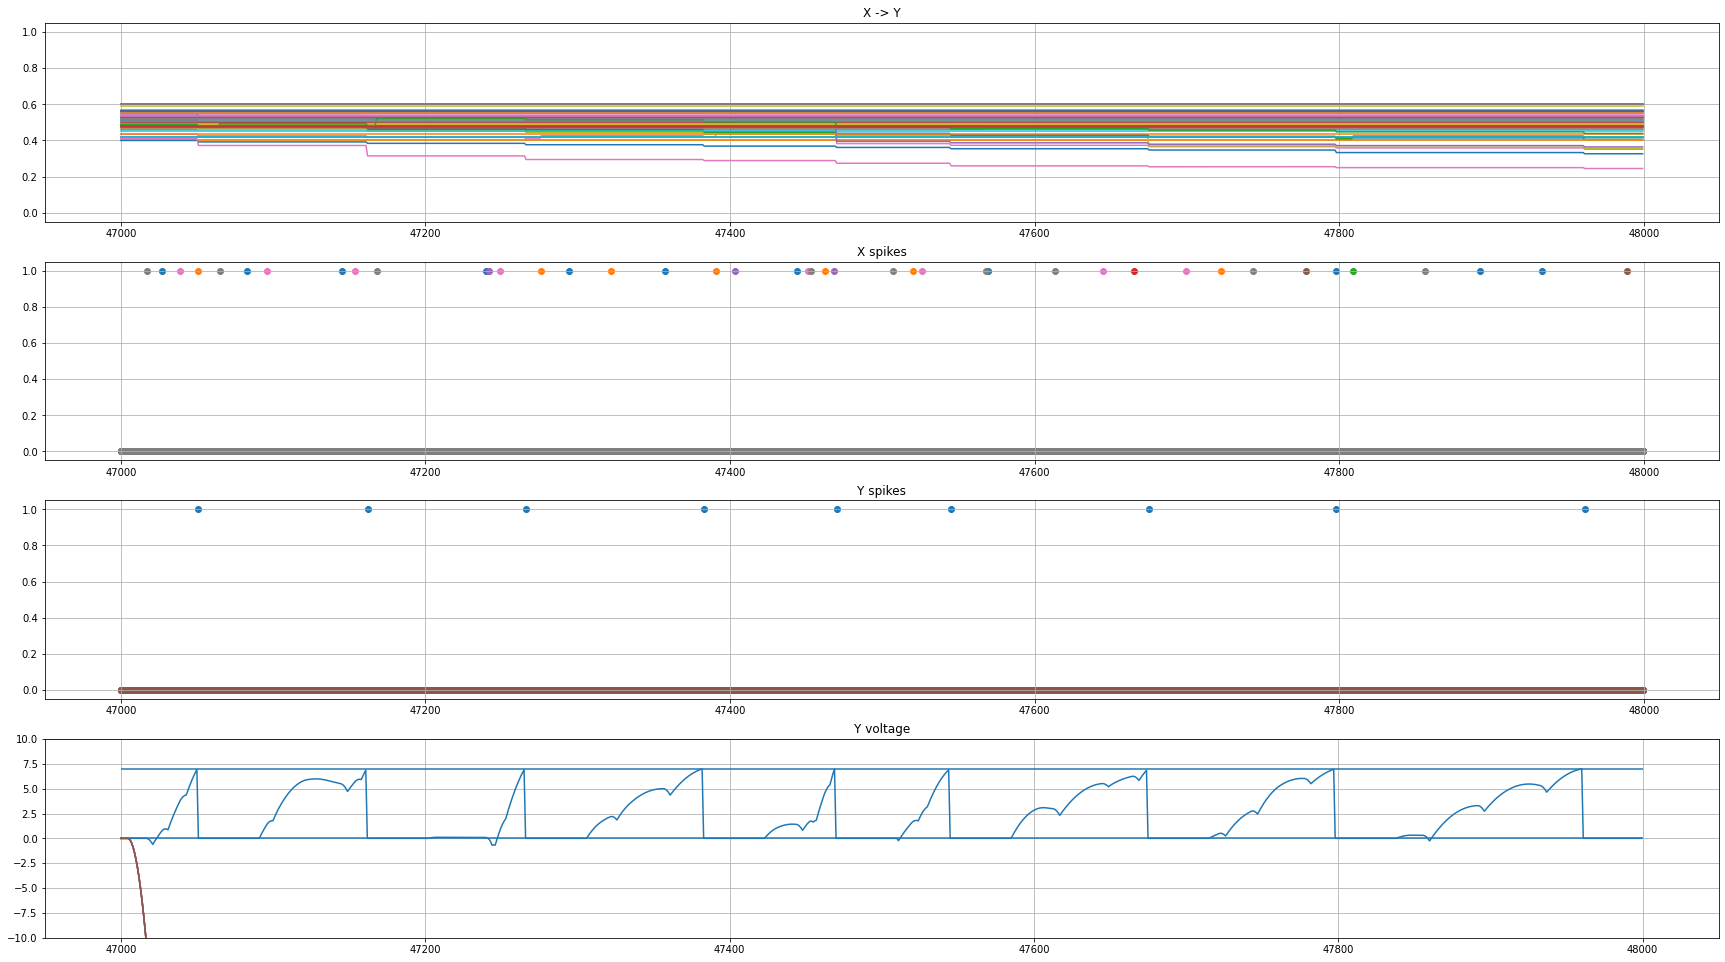

In [4]:

#---------------FILE TO READ--------------------------------------------------------

res_temp = np.loadtxt("write_r.txt", dtype=float, delimiter = "\t").reshape([num_in*num_of_classes])

cond_temp = 1/res_temp

weights_temp = (cond_temp - np.min(cond_states))/(np.max(cond_states) - np.min(cond_states))

network.connections[('X','Y')].w = torch.nn.Parameter(torch.Tensor(np.asarray(weights_temp).reshape([num_in,num_of_classes])), requires_grad=False)

# plot   
# Weights

fig_w = plt.figure(figsize=(30, 30))
plt.subplot(7,1,1)
plt.title('X -> Y')
for j in range(weights.size(1)):
    plt.plot(np.arange(i*weights.size(0), (i+1)*weights.size(0)), weights[:,j].numpy(), label=str(j))
#plt.legend(loc='upper right')
plt.ylim(-0.05, 1.05)
plt.grid()

# Spikes
plt.subplot(7,1,2)
plt.title('X spikes')
spikes = recordings[('X')]['s']
for j in range(spikes.size(2)):
    #plt.plot(np.arange(i*spikes.size(0), (i+1)*spikes.size(0)), spikes[:,:,j].numpy(), label=str(j))
    plt.scatter(np.arange(i*spikes.size(0), (i+1)*spikes.size(0)), spikes[:,:,j].numpy(), label=str(j))
#plt.legend(loc='upper right')
plt.ylim(-0.05, 1.05)
plt.grid()

plt.subplot(7,1,3)
plt.title('Y spikes')
spikes = recordings[('Y')]['s']
for j in range(spikes.size(2)):
    #plt.plot(np.arange(i*spikes.size(0), (i+1)*spikes.size(0)), spikes[:,:,j].numpy(), label=str(j))
    plt.scatter(np.arange(i*spikes.size(0), (i+1)*spikes.size(0)), spikes[:,:,j].numpy(), label=str(j))
#plt.legend(loc='upper right')
plt.ylim(-0.05, 1.05)
plt.grid()

# Voltages
plt.subplot(7,1,4)
plt.title('Y voltage')
voltages = recordings[('Y')]['v']
for j in range(voltages.size(2)):
    plt.plot(np.arange(i*voltages.size(0), (i+1)*voltages.size(0)), voltages[:,:,j].numpy(), label=str(j))
#plt.legend(loc='upper right')
plt.hlines([reset, thresh], i*voltages.size(0), (i+1)*voltages.size(0))
plt.ylim(-10, 10)
plt.grid()

if enable_astrocyte:

    plt.subplot(7,1,6)
    plt.title('Astrocyte')
    value = recordings[('I')]['G']
    for j in range(value.size(1)):
        plt.plot(np.arange(i*value.size(0), (i+1)*value.size(0)), value[:,j].numpy(), label=str(j))
    #plt.legend(loc='upper right')
    #plt.hlines([reset, thresh], i*value.size(0), (i+1)*value.size(0))
    plt.grid()


display.clear_output(wait=True)
display.display(fig_w, display_id = 'weights')

network.reset_()

plt.close(fig_w)


### Test

In [5]:
network_test = Network()

input_layer = Input(n=num_in, 
                    traces=True, 
                    thresh=thresh,
                    rest = reset,
                    reset=reset,
                    refrac=refrac)


output_layer = LIFNodes(n=num_of_classes, 
                       traces=True, 
                       thresh=thresh*torch.ones(num_of_classes),
                       rest = reset,
                       reset=reset,
                       refrac=refrac)


conn_XY = Connection(input_layer, 
                     output_layer, 
                     impulse_amplitude = 0.5,
                     impulse_amplitude_2 = 0.5,
                     impulse_length = 40,
                     impulse_shape_factor = 0.9,
                     invert = True,
                     update_rule=NoOp,
                     w=network.connections[('X','Y')].w, 
                     nu=[25, 50], 
                     wmin=wmin, 
                     wmax=wmax,
                     weight_decay=weight_decay,
                     post_spike_weight_decay=post_spike_weight_decay
                     )

network_test.add_layer(input_layer, name='X')
network_test.add_layer(output_layer, name='Y')

network_test.add_connection(conn_XY, source='X', target='Y')

GlobalMonitor = NetworkMonitor(network_test, state_vars=('v', 's', 'w'))
    
network_test.add_monitor(GlobalMonitor, name='Network_test')

len_dataset_test = 10
input_data_test, input_data_2_test = dataset(len_dataset_test)
 
input_data_test *= intensity

data_loader_test = bernoulli_loader(data=(input_data_test/1000)*dt, time=time)

wins = 0

for i in range(num_of_classes*len_dataset_test):
    
    sample = next(data_loader_test)

    inpts = {'X': sample}
    
    network_test.run(inpts=inpts, time=time)#, injects_v = injects_v)

    recordings_test = network_test.monitors['Network_test'].get()

    spikes = np.asarray(recordings_test[('Y')]['s'])

    spike_rates = np.squeeze(np.sum(spikes, axis = 0))

    if np.sum(spike_rates):
        
        if (i % num_of_classes) == np.argmax(np.squeeze(np.sum(spikes, axis = 0))):
            
            wins += 1
            
    print(i)
    display.clear_output(wait=True)
    network_test.reset_()

print('Accuracy = ' + str(wins/(num_of_classes*len_dataset_test)))

Accuracy = 0.06666666666666667


In [6]:
wins

4